In [115]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

In [116]:
dataset = pd.read_csv("/content/drive/MyDrive/IDS_Lab_9_datasets/car_price_dataset.csv")

In [117]:
dataset.shape

(2020, 8)

In [118]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2020 entries, 0 to 2019
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         2020 non-null   object 
 1   model_year    2020 non-null   object 
 2   engine_size   1919 non-null   float64
 3   mileage       1918 non-null   float64
 4   fuel_type     1919 non-null   object 
 5   transmission  2020 non-null   object 
 6   owner_count   2020 non-null   int64  
 7   price         2020 non-null   float64
dtypes: float64(3), int64(1), object(4)
memory usage: 126.4+ KB


In [119]:
dataset.head()

,brand,model_year,engine_size,mileage,fuel_type,transmission,owner_count,price
0,Audi,2009,1.9,204316.0,Petrol,Manual,2,327087.0
1,Hyundai,2021,1.7,201497.0,Diesel,Manual,3,226505.0
2,Mercedes,2006,0.8,87844.0,Diesel,Manual,2,200000.0
3,Kia,2008,3.5,NaN,Diesel,Automatic,1,538439.0
4,Audi,2016,4.4,95697.0,Petrol,Manual,2,946333.0


In [120]:
dataset.isnull().sum()

,0
brand,0
model_year,0
engine_size,101
mileage,102
fuel_type,101
transmission,0
owner_count,0
price,0


In [121]:
dataset.duplicated().sum()

np.int64(20)

In [122]:
dataset['engine_size'] = dataset['engine_size'].fillna(dataset['engine_size'].mean())
dataset['mileage'] = dataset['mileage'].fillna(dataset['mileage'].mean())

dataset['fuel_type'] = dataset['fuel_type'].fillna(dataset['fuel_type'].mode()[0])

In [123]:
dataset = dataset.drop_duplicates()

In [124]:
dataset.duplicated().sum()

np.int64(0)

In [125]:
print(dataset["brand"].unique())
print(dataset["fuel_type"].unique())
print(dataset["transmission"].unique())
print(dataset['model_year'].unique())


['Audi' 'Hyundai' 'Mercedes' 'Kia' 'Nissan' 'Suzuki' 'BMW' 'Honda'
 'Toyota' 'Ford']
['Petrol' 'Diesel' 'Hybrid']
['Manual' 'Automatic']
['2009' '2021' '2006' '2008' '2016' '2010' '2023' '2013' '2018' '2003'
 '2005' '2012' '2007' '2004' '2000' '2002' '2001' '2011' '2020' '2017'
 '2022' '2019' '2014' '2015' 'unknown']


In [126]:
dataset['model_year'] = dataset['model_year'].replace('unknown', pd.NA)
dataset['model_year'] = pd.to_numeric(dataset['model_year'], errors='coerce')
dataset['model_year'] = dataset['model_year'].fillna(dataset['model_year'].median())

In [127]:
label_encoder = LabelEncoder()
dataset["brand"] = label_encoder.fit_transform(dataset["brand"])
joblib.dump(label_encoder, "brand_encoder.pkl")
dataset["fuel_type"] = label_encoder.fit_transform(dataset["fuel_type"])
joblib.dump(label_encoder, "fuel_type_encoder.pkl")
dataset["transmission"] = label_encoder.fit_transform(dataset["transmission"])
joblib.dump(label_encoder, "transmission_encoder.pkl")

['transmission_encoder.pkl']

In [128]:
dataset.shape

(2000, 8)

In [129]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   brand         2000 non-null   int64  
 1   model_year    2000 non-null   float64
 2   engine_size   2000 non-null   float64
 3   mileage       2000 non-null   float64
 4   fuel_type     2000 non-null   int64  
 5   transmission  2000 non-null   int64  
 6   owner_count   2000 non-null   int64  
 7   price         2000 non-null   float64
dtypes: float64(4), int64(4)
memory usage: 140.6 KB


In [130]:
dataset.head()

,brand,model_year,engine_size,mileage,fuel_type,transmission,owner_count,price
0,0,2009.0,1.9,204316.000000,2,1,2,327087.0
1,4,2021.0,1.7,201497.000000,0,1,3,226505.0
2,6,2006.0,0.8,87844.000000,0,1,2,200000.0
3,5,2008.0,3.5,154835.631387,0,0,1,538439.0
4,0,2016.0,4.4,95697.000000,2,1,2,946333.0


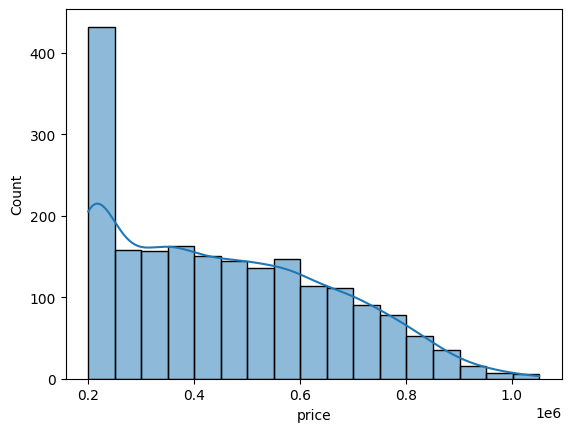

In [131]:
sns.histplot(dataset['price'], kde=True)
plt.show()

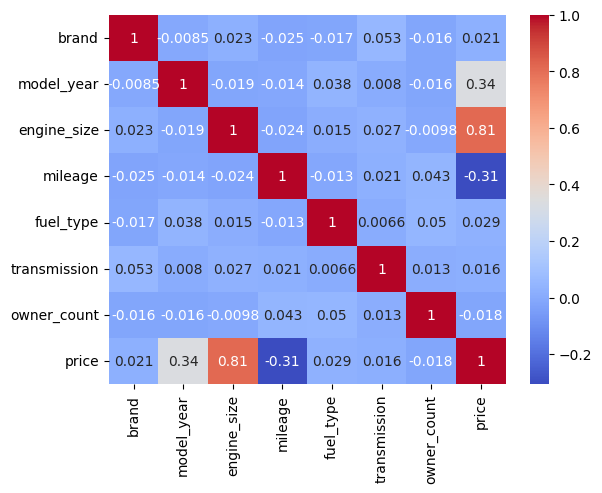

In [132]:
sns.heatmap(dataset.corr(), annot=True, cmap="coolwarm")
plt.show()

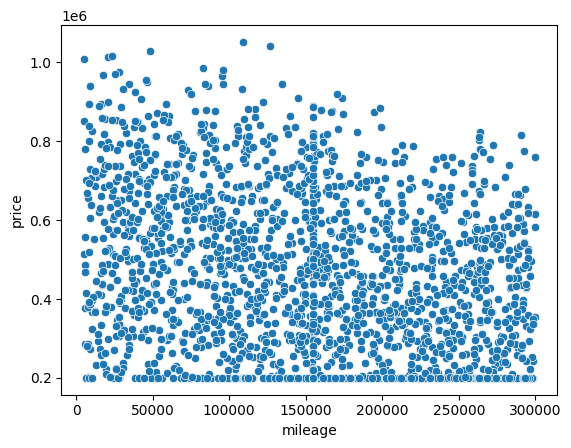

In [133]:
sns.scatterplot(x=dataset["mileage"], y=dataset['price'])
plt.show()

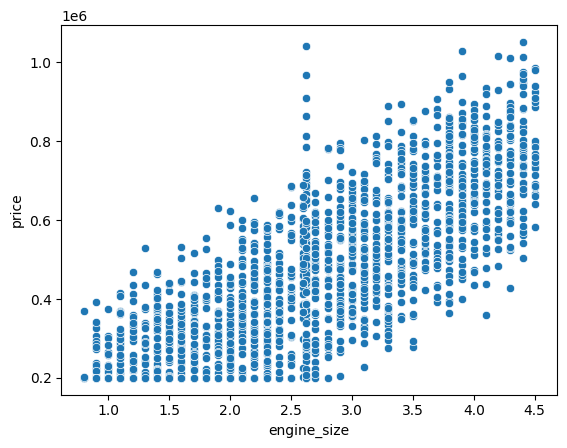

In [134]:
sns.scatterplot(x=dataset["engine_size"], y=dataset['price'])
plt.show()

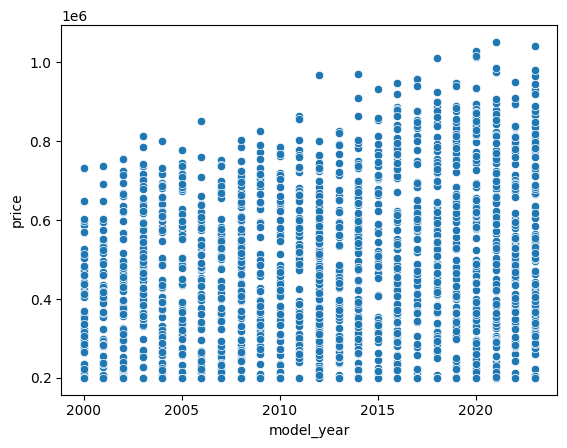

In [135]:
sns.scatterplot(x=dataset["model_year"], y=dataset['price'])
plt.show()

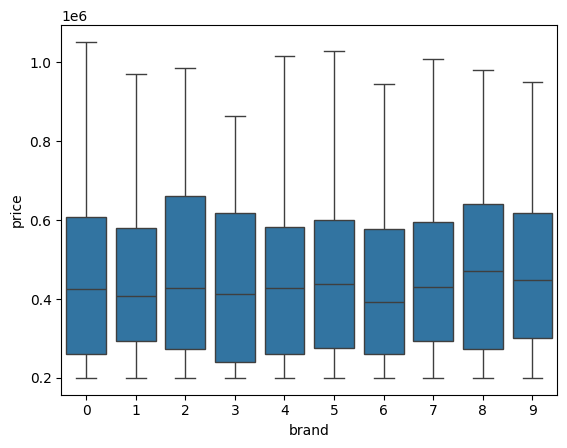

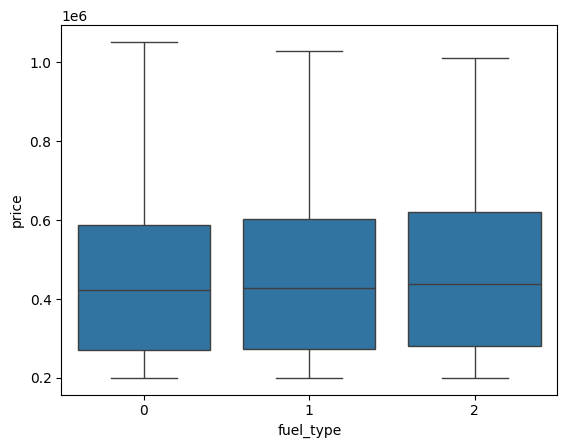

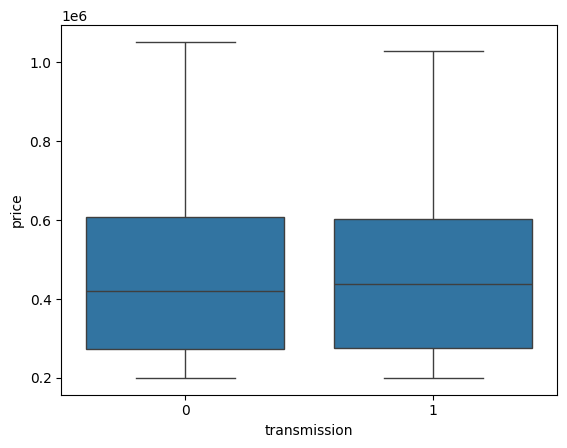

In [136]:
sns.boxplot(x=dataset["brand"], y=dataset['price'])
plt.show()

sns.boxplot(x=dataset["fuel_type"], y=dataset['price'])
plt.show()

sns.boxplot(x=dataset["transmission"], y=dataset['price'])
plt.show()

In [137]:
scaler = StandardScaler()
dataset[["model_year", "engine_size", "mileage", "owner_count"]] = scaler.fit_transform(dataset[["model_year", "engine_size", "mileage", "owner_count"]])

In [138]:
y = dataset["price"]
x = dataset.drop("price", axis=1)

In [139]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [140]:
linear_regression = LinearRegression()
linear_model = linear_regression.fit(x_train, y_train)
linear_results = linear_model.predict(x_test)

In [141]:
random_forest = RandomForestRegressor(random_state=42)
rf_model = random_forest.fit(x_train, y_train)
rf_results = rf_model.predict(x_test)

In [142]:
mean_absolute_error(y_test, linear_results)

61097.40228013726

In [143]:
mean_squared_error(y_test, linear_results)

6767971845.651447

In [144]:
r2_score(y_test, linear_results)

0.8249910756424687

In [145]:
np.sqrt(mean_squared_error(y_test, linear_results))

np.float64(82267.68409072573)

In [146]:
mean_absolute_error(y_test, rf_results)

56497.31705

In [147]:
mean_squared_error(y_test, rf_results)

6795414542.243403

In [148]:
r2_score(y_test, rf_results)

0.8242814514121146

In [149]:
np.sqrt(mean_squared_error(y_test, rf_results))

np.float64(82434.30440201097)

In [150]:
print("Please enter the following car details to predict the price:")

user_input = {
    "brand": input("Brand: "),
    "model_year": int(input("Model Year: ")),
    "engine_size": float(input("Engine Size: ")),
    "mileage": float(input("Mileage: ")),
    "fuel_type": input("Fuel Type (Petrol/Diesel/Hybrid): "),
    "transmission": input("Transmission (Manual/Automatic): "),
    "owner_count": int(input("Owner Count: "))
}

data = pd.DataFrame([user_input])

Please enter the following car details to predict the price:
Brand: Suzuki
Model Year: 2020
Engine Size: 4.5
Mileage: 200000
Fuel Type (Petrol/Diesel/Hybrid): Hybrid
Transmission (Manual/Automatic): Automatic
Owner Count: 1


In [151]:
label_encoder = joblib.load("brand_encoder.pkl")
data["brand"] = label_encoder.transform(data["brand"])
label_encoder = joblib.load("fuel_type_encoder.pkl")
data["fuel_type"] = label_encoder.transform(data["fuel_type"])
label_encoder = joblib.load("transmission_encoder.pkl")
data["transmission"] = label_encoder.transform(data["transmission"])
data[["model_year", "engine_size", "mileage", "owner_count"]] = scaler.transform(data[["model_year", "engine_size", "mileage", "owner_count"]])

In [152]:
print("Linear Regression Prediction:", (linear_model.predict(data))[0])
print("Random Forest Prediction:", (rf_model.predict(data))[0])

Linear Regression Prediction: 809723.0568879275
Random Forest Prediction: 804854.83


In [153]:
joblib.dump(linear_model, "car_price_linear_model.pkl")
joblib.dump(rf_model, "car_price_rf_model.pkl")
joblib.dump(scaler, "car_scaler.pkl")

['car_scaler.pkl']